In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

In [11]:
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/PA 01/Question 2 - Leaderboard"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/PA 01/Question 2 - Leaderboard


In [12]:
data_dir = "."
out_dir = "figs"
os.makedirs(out_dir, exist_ok=True)
H, YEAR = 168, 8766

In [13]:
def acf(x, nlags):
    x = x - x.mean(); n = len(x); f = np.fft.rfft(x, 2 * n)
    a = np.fft.irfft(f * np.conj(f))[: nlags + 1]
    return a / a[0]

In [14]:
def baseline_block_rmse(v, K=52):
    n, out = len(v), {"last value": [], "train mean": [], "decay to mean (tau=12)": []}
    h = np.arange(1, H + 1)
    for i in range(K):
        o = n - H * (K - i); y, hist = v[o:o + H], v[:o]; mu, last = hist.mean(), hist[-1]
        r = lambda p: np.sqrt(np.mean((y - p) ** 2))
        out["last value"].append(r(last)); out["train mean"].append(r(mu))
        out["decay to mean (tau=12)"].append(r(mu + (last - mu) * np.exp(-h / 12)))
    return {k: np.array(a) for k, a in out.items()}

n=43656, mean=98.2, sd=90.8, min/max=0/994, q50/q90/q99=[ 73. 218. 418.]
ACF lag 1/6/12/24/48/168: [np.float64(0.966), np.float64(0.749), np.float64(0.57), np.float64(0.401), np.float64(0.158), np.float64(0.028)]
  spectral power at period 24: 0.90%
  spectral power at period 168: 0.45%
  spectral power at period 8766: 3.03%
  baseline last value               mean block-RMSE  114.1  SD  91.6  range 29-448
  baseline train mean               mean block-RMSE   83.2  SD  41.6  range 37-269
  baseline decay to mean (tau=12)   mean block-RMSE   78.7  SD  38.8  range 36-267

Saved EDA figures to figs/fig_eda.pdf and .png

corr(feature(t), log1p y(t)): {'feature_A': 0.31, 'feature_B': 0.02, 'feature_C': -0.16, 'feature_D': -0.35, 'feature_E': 0.03, 'feature_F': -0.05, 'feature_G': -0.06, 'feature_H': -0.35, 'feature_I': 0.23, 'feature_J': 0.18}
binary features mutually exclusive: True
non-zero fraction of E,F in history: 0.008 0.041 | in horizon: 0.0 0.0
horizon mean vs history mean (A,B,C,D

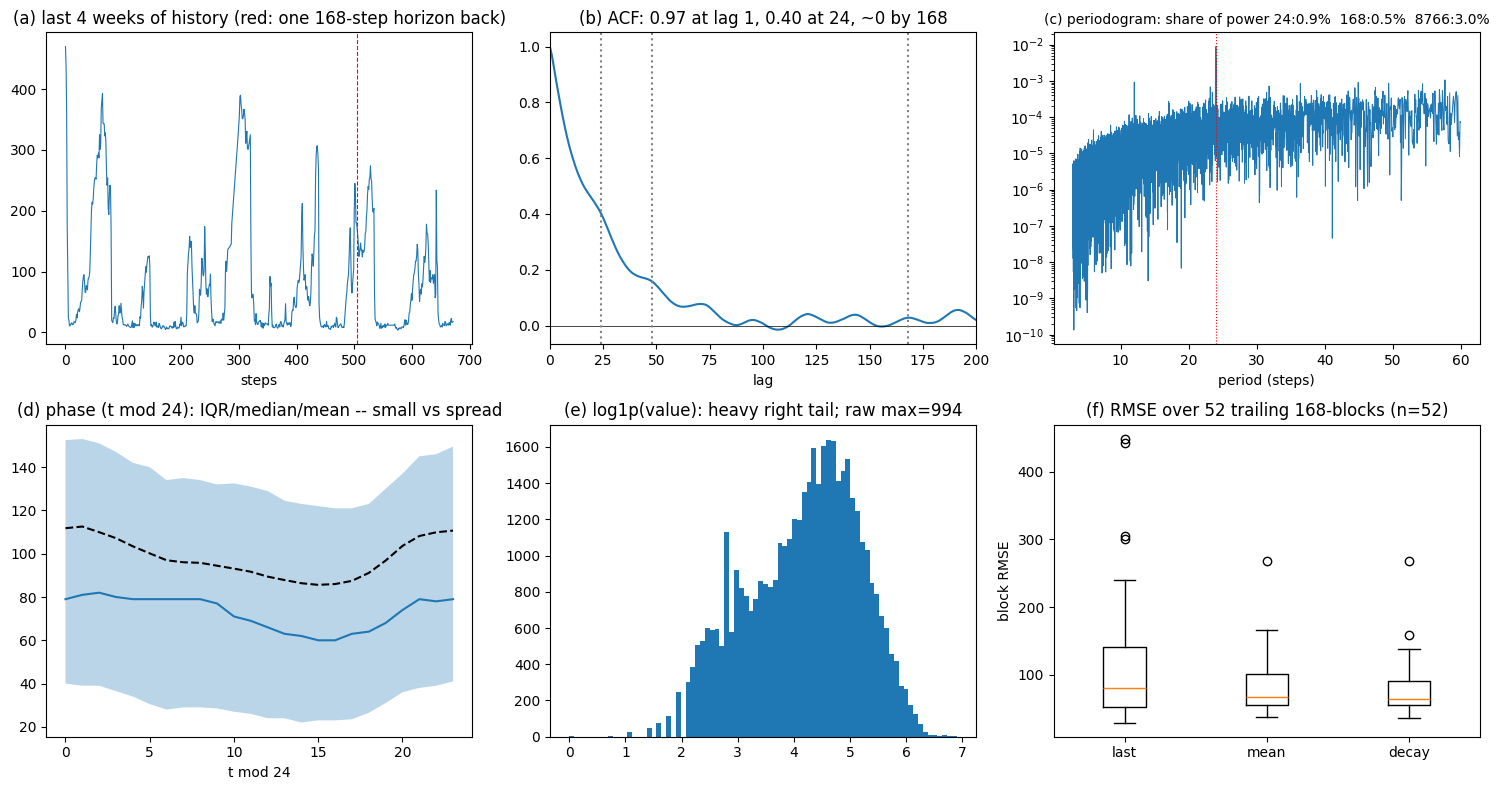

In [18]:
# Load Data
tr = pd.read_csv(f"Data/student_train.csv")
ex = pd.read_csv(f"Data/optional_external_data.csv")
v = tr.value.to_numpy(float); n = len(v); X = ex.iloc[:, 1:]; t0 = np.arange(n)

# Print Statistics
print(f"n={n}, mean={v.mean():.1f}, sd={v.std():.1f}, min/max={v.min():.0f}/{v.max():.0f}, "
      f"q50/q90/q99={np.quantile(v,[.5,.9,.99]).round(0)}")
A = acf(v, 400)
print("ACF lag 1/6/12/24/48/168:", [round(A[l], 3) for l in (1, 6, 12, 24, 48, 168)])
P = np.abs(np.fft.rfft(v - v.mean())) ** 2; fr = np.fft.rfftfreq(n); tot = P[1:].sum()
for per in (24, 168, YEAR):
    k = np.argmin(np.abs(fr - 1 / per))
    print(f"  spectral power at period {per}: {P[k-1:k+2].sum()/tot*100:.2f}%")

base = baseline_block_rmse(v)
for k, b in base.items():
    print(f"  baseline {k:24s} mean block-RMSE {b.mean():6.1f}  SD {b.std():5.1f}  range {b.min():.0f}-{b.max():.0f}")

# Generate Figure
fig, ax = plt.subplots(2, 3, figsize=(15, 8)); ax = ax.ravel()
ax[0].plot(v[-24 * 28:], lw=.8); ax[0].axvline(24 * 28 - H, c="r", ls="--", lw=.8)
ax[0].set_title("(a) last 4 weeks of history (red: one 168-step horizon back)"); ax[0].set_xlabel("steps")
ax[1].plot(np.arange(401), A); ax[1].axhline(0, c="k", lw=.5); [ax[1].axvline(l, c="gray", ls=":") for l in (24, 48, 168)]
ax[1].set_xlim(0, 200); ax[1].set_title("(b) ACF: 0.97 at lag 1, 0.40 at 24, ~0 by 168"); ax[1].set_xlabel("lag")

kk = (fr > 1 / 60) & (fr < 1 / 3); ax[2].semilogy(1 / fr[kk], P[kk] / tot, lw=.7); ax[2].axvline(24, c="r", ls=":", lw=.8)
sh = lambda per: P[np.argmin(np.abs(fr - 1 / per)) - 1:np.argmin(np.abs(fr - 1 / per)) + 2].sum() / tot * 100
ax[2].set_title("(c) periodogram: share of power 24:%.1f%%  168:%.1f%%  8766:%.1f%%" % (sh(24), sh(168), sh(YEAR)), fontsize=10)
ax[2].set_xlabel("period (steps)")

ph = t0 % 24; prof = np.array([[np.quantile(v[ph == h], q) for h in range(24)] for q in (.25, .5, .75)])
ax[3].fill_between(range(24), prof[0], prof[2], alpha=.3); ax[3].plot(prof[1]); ax[3].plot([v[ph == h].mean() for h in range(24)], "k--")
ax[3].set_title("(d) phase (t mod 24): IQR/median/mean -- small vs spread"); ax[3].set_xlabel("t mod 24")
ax[4].hist(np.log1p(v), 80); ax[4].set_title("(e) log1p(value): heavy right tail; raw max=%d" % v.max())

data = list(base.values()); ax[5].boxplot(data, tick_labels=["last", "mean", "decay"]); ax[5].set_ylabel("block RMSE")
ax[5].set_title("(f) RMSE over 52 trailing 168-blocks (n=%d)" % len(data[0]))
plt.tight_layout()

plt.savefig(f"{out_dir}/fig_eda.pdf", dpi=130)
plt.savefig(f"{out_dir}/fig_eda.png", dpi=130)
print(f"\nSaved EDA figures to {out_dir}/fig_eda.pdf and .png")

# Covariates Analysis
lv = np.log1p(v); Xt = X.iloc[:n]
print("\ncorr(feature(t), log1p y(t)):", Xt.corrwith(pd.Series(lv)).round(2).to_dict())
print("binary features mutually exclusive:", bool((Xt[['feature_G','feature_H','feature_I','feature_J']].sum(axis=1) == 1).all()))
print("non-zero fraction of E,F in history:", (Xt.feature_E != 0).mean().round(3), (Xt.feature_F != 0).mean().round(3),
      "| in horizon:", (X.iloc[n:].feature_E != 0).mean(), (X.iloc[n:].feature_F != 0).mean())
print("horizon mean vs history mean (A,B,C,D):",
      {c: (round(X[c].iloc[n:].mean(), 1), round(Xt[c].mean(), 1)) for c in ["feature_A", "feature_B", "feature_C", "feature_D"]})